# Chunking legal text for RAG: structure-aware vs fixed vs semantic chunks

This notebook splits four Indian consumer-protection Rules and three open textbooks in four ways (fixed 256-token windows, fixed 512-token windows, embedding-based semantic chunks, and chunks that follow the documents' own rules and sections) and measures how well one retriever finds the gold passages under each. You get working implementations of all four chunkers, a relevance rule that works for any chunking, and Recall@5, nDCG@10 and token-budget coverage with paired bootstrap confidence intervals.

Data: the [VeriDex RAG corpus](https://www.kaggle.com/datasets/swapnilshukla007/veridex-rag-corpus) dataset (7 documents, 157 questions, 106 of them answerable with gold passages). Run time: about 30 minutes on a 4-thread laptop CPU (29.7 minutes measured), most of it spent embedding chunks. No GPU needed; internet is used once to download `bge-small-en-v1.5`.

Links: [live app](https://swapnil007-curious.github.io/VeriDex/) · [GitHub repo](https://github.com/Swapnil007-Curious/VeriDex) · paper (link to be added)

Part 1 of the 5-part VeriDex series on building and checking a RAG system.

## Contents

1. Setup
2. The documents and their structure
3. Four chunkers
4. What the chunks look like
5. A relevance rule that works for any chunking
6. Retrieval and metrics
7. Paired bootstrap comparison
8. One question, four chunkings
9. What we found

## 1. Setup

Kaggle's image already has PyTorch, transformers, pandas and matplotlib. The cell below installs `sentence-transformers` only if it is missing. All tunable values sit in the constants cell.

In [1]:
import importlib.util
import subprocess
import sys


def ensure(package: str, module: str) -> None:
    """Install a pinned package only when the environment does not already provide the module."""
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)


ensure("sentence-transformers==6.2.0", "sentence_transformers")

In [2]:
import bisect
import json
import os
import random
import re
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

'false'

In [3]:
SEED = 42  # seeds Python, NumPy and PyTorch; also the bootstrap generator
EMBED_MODEL = "BAAI/bge-small-en-v1.5"  # tokenizer for all chunkers, semantic-chunk embeddings and the retriever
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "  # bge v1.5 query prefix
FIXED_CONFIGS = {"fixed_256": (256, 32), "fixed_512": (512, 64)}  # name: (window tokens, overlap tokens)
STRUCT_MAX_TOKENS = 384  # a rule or section longer than this is split along its sub-rules and clauses
STRUCT_MIN_TOKENS = 48  # neighbouring pieces shorter than this are merged
SEM_PERCENTILE = 90.0  # semantic breakpoint: distance above this percentile of a document's distances
SEM_MIN_TOKENS, SEM_MAX_TOKENS = 64, 512  # semantic chunk size limits
K_RECALL, K_RANK = 5, 10  # Recall@5; MRR@10 and nDCG@10
BUDGET = 1024  # coverage: gold nodes inside the top chunks that fit a 1024-token context
N_BOOT = 1000  # bootstrap resamples
BASELINE = "fixed_512"  # naive RAG chunking that the others are compared with
CHUNKERS = ["fixed_256", "fixed_512", "semantic", "structural"]
COLLECTION_LABELS = {"consumer_rules": "Consumer rules", "cs_ai": "CS / AI textbooks"}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Okabe-Ito colours, distinguishable with the common forms of colour blindness
PALETTE = {"fixed_256": "#E69F00", "fixed_512": "#56B4E9", "semantic": "#009E73", "structural": "#0072B2"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def set_seed(seed: int = SEED) -> None:
    """Seed every random number generator the notebook touches."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def takeaway(text: str) -> None:
    """Show the one-line conclusion under a plot."""
    display(Markdown(f"> {text}"))


set_seed()
NOTEBOOK_START = time.time()
print(f"device: {DEVICE}, torch {torch.__version__}")

device: cpu, torch 2.15.0+cpu


In [4]:
def find_data_dir() -> Path:
    """Locate the veridex-rag-corpus dataset under /kaggle/input (or VERIDEX_DATA_DIR when run elsewhere)."""
    if os.environ.get("VERIDEX_DATA_DIR"):
        return Path(os.environ["VERIDEX_DATA_DIR"])
    for manifest in Path("/kaggle/input").glob("**/MANIFEST.json"):
        if json.loads(manifest.read_text(encoding="utf-8")).get("dataset") == "veridex-rag-corpus":
            return manifest.parent
    raise FileNotFoundError("Add the veridex-rag-corpus dataset to this notebook (Add Input).")


def read_jsonl(path: Path) -> list[dict]:
    """Read a JSON-lines file into a list of dicts."""
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


DATA_DIR = find_data_dir()
WORK_DIR = Path(os.environ.get("VERIDEX_WORK_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)

documents = pd.read_csv(DATA_DIR / "documents.csv")
questions = read_jsonl(DATA_DIR / "questions" / "questions.jsonl")
node_rows = read_jsonl(DATA_DIR / "structure" / "nodes.jsonl")
texts = {d: (DATA_DIR / "text" / f"{d}.txt").read_text(encoding="utf-8") for d in documents.doc_id}

summary = documents.assign(
    questions=documents.collection.map(Counter(q["collection"] for q in questions)),
    nodes=documents.doc_id.map(Counter(n["doc_id"] for n in node_rows)),
)[["collection", "doc_id", "title", "licence", "n_chars", "nodes"]]
summary

,collection,doc_id,title,licence,n_chars,nodes
0,consumer_rules,ecom2020,"The Consumer Protection (E-Commerce) Rules, 2020",Gazette of India notification; reproduction pe...,17354,95
1,consumer_rules,commissions2020,The Consumer Protection (Consumer Disputes Red...,Gazette of India notification; reproduction pe...,22704,101
2,consumer_rules,jurisdiction2021,The Consumer Protection (Jurisdiction of the D...,Gazette of India notification; reproduction pe...,2265,12
3,consumer_rules,mediation2020,"The Consumer Protection (Mediation) Rules, 2020",Gazette of India notification; reproduction pe...,3793,28
4,cs_ai,d2l,Dive into Deep Learning,CC BY-SA 4.0 International,494180,675
5,cs_ai,progit,Pro Git,CC BY-NC-SA 3.0 Unported,152922,263
6,cs_ai,ods,Open Data Structures (in pseudocode),CC BY 2.5 Canada,173602,320


The consumer-law collection in VeriDex also holds the Consumer Protection Act, 2019. It is not in the Kaggle dataset because of its licence (an Act may only be reproduced together with commentary), so the questions whose answers sit in the Act were removed. That leaves a small legal corpus: four Rules, about 46,000 characters. The three textbooks add a second, larger corpus with a different structure.

In [5]:
qdf = pd.DataFrame(questions)
pd.crosstab([qdf.collection, qdf.answerable], qdf.split, margins=True)

split                      dev  test  All
collection     answerable                
consumer_rules False        14    17   31
               True         14    32   46
cs_ai          False         4    16   20
               True         20    40   60
All                         52   105  157

## 2. The documents and their structure

Each document comes with a parsed hierarchy: rules contain sub-rules, sub-rules contain clauses, textbook chapters contain numbered sections and code blocks. Every node stores character offsets into the cleaned text, so a node's text is just a slice. The parser itself (regular expressions for Indian statute numbering, font and numbering cues for textbook headings) lives in the VeriDex repository under `src/ragsys/structure/`; this notebook starts from its output.

In [6]:
UNIT_LEVELS = {"section", "rule", "schedule"}


@dataclass
class Node:
    """One structural unit (rule, sub-rule, clause, textbook section, ...) of a document."""

    doc_id: str
    doc_title: str
    doc_type: str
    node_id: str
    level: str
    number: str | None
    heading: str | None
    parent_id: str | None
    children: list
    char_start: int
    char_end: int
    defined_term: str | None
    order: int

    @property
    def is_unit(self) -> bool:
        """Top-level retrieval unit: a section, rule or schedule, or a top-level heading."""
        return self.level in UNIT_LEVELS or (self.level == "heading" and self.parent_id is None)


@dataclass
class Doc:
    """A document's cleaned text with its node tree."""

    doc_id: str
    title: str
    doc_type: str
    text: str
    nodes: list

    def __post_init__(self) -> None:
        self.nodes = sorted(self.nodes, key=lambda n: n.order)
        self.by_id = {n.node_id: n for n in self.nodes}

    @property
    def short_title(self) -> str:
        t = self.title.strip()
        return t[4:] if t.lower().startswith("the ") else t

    def ancestors(self, node: Node) -> list:
        """The node itself, its parent, grandparent and so on."""
        out = [node]
        while out[-1].parent_id and out[-1].parent_id in self.by_id:
            out.append(self.by_id[out[-1].parent_id])
        return out


NODE_KEYS = Node.__dataclass_fields__.keys()
docs: dict[str, Doc] = {}
for doc_id, text in texts.items():
    rows = [r for r in node_rows if r["doc_id"] == doc_id]
    nodes = [Node(**{k: r[k] for k in NODE_KEYS}) for r in rows]
    docs[doc_id] = Doc(doc_id, rows[0]["doc_title"], rows[0]["doc_type"], text, nodes)
doc_collection = dict(zip(documents.doc_id, documents.collection))


def print_outline(doc: Doc, node_id: str, max_lines: int = 14) -> None:
    """Print a node's subtree as an indented outline with token-free character lengths."""
    lines = []

    def walk(nid: str, depth: int) -> None:
        n = doc.by_id[nid]
        label = n.heading or (doc.text[n.char_start:n.char_end].split("\n")[0][:60])
        lines.append(f"{'  ' * depth}{n.level:<11} {n.node_id:<28} {n.char_end - n.char_start:>6} chars  {label[:60]}")
        for c in n.children:
            if c in doc.by_id:
                walk(c, depth + 1)

    walk(node_id, 0)
    print("\n".join(lines[:max_lines]) + ("\n  ..." if len(lines) > max_lines else ""))


print_outline(docs["ecom2020"], "ecom2020:r4")

rule        ecom2020:r4                    3715 chars  Duties of e-commerce entities
  subsection  ecom2020:r4(1)                  652 chars  (1) An e-commerce entity shall:
    clause      ecom2020:r4(1)(a)               428 chars  (a) be a company incorporated under the Companies Act, 1956 
    clause      ecom2020:r4(1)(a)~2             191 chars  (a) appoint a nodal person of contact or an alternate senior
  subsection  ecom2020:r4(2)                  439 chars  (2) Every e-commerce entity shall provide the following info
    clause      ecom2020:r4(2)(a)                40 chars  (a) legal name of the e-commerce entity;
    clause      ecom2020:r4(2)(b)                70 chars  (b) principal geographic address of its headquarters and all
    clause      ecom2020:r4(2)(c)                40 chars  (c) name and details of its website; and
    clause      ecom2020:r4(2)(d)               123 chars  (d) contact details like e-mail address, fax, landline and m
  subsection  ecom2020:r4(3)

Rule 4 of the E-Commerce Rules is one unit with nine sub-rules, some of them with lettered clauses. A chunker that knows this tree can keep sub-rule (3) in one piece and label it "Rule 4 > Sub-rule (3)". A fixed window cannot.

## 3. Four chunkers

All four chunkers count tokens with the `bge-small-en-v1.5` tokenizer (no special tokens), so the sizes are comparable. The code is a compact port of the VeriDex chunkers in `src/ragsys/chunking/`; at the end of this section we check that it reproduces the chunk files shipped in the dataset.

In [7]:
class TokenCounter:
    """Token counts and character offsets with a Hugging Face fast tokenizer (no special tokens)."""

    def __init__(self, model_name: str) -> None:
        from transformers import AutoTokenizer

        backend = AutoTokenizer.from_pretrained(model_name).backend_tokenizer
        backend.no_truncation()
        backend.no_padding()
        self.backend = backend

    def count(self, text: str) -> int:
        return len(self.backend.encode(text, add_special_tokens=False).ids) if text else 0

    def count_many(self, texts: list) -> list:
        return [len(e.ids) for e in self.backend.encode_batch(texts, add_special_tokens=False)] if texts else []

    def offsets(self, text: str) -> list:
        """Character span of every token of `text`."""
        if not text:
            return []
        return [(int(a), int(b)) for a, b in self.backend.encode(text, add_special_tokens=False).offsets]


tok = TokenCounter(EMBED_MODEL)


@dataclass
class Chunk:
    """A chunk: a character span of one document plus the text that gets embedded."""

    chunker: str
    doc_id: str
    char_start: int
    char_end: int
    text: str
    n_tokens: int
    heading_path: str = ""

### Fixed windows

Slide a window of `size` tokens with `overlap` tokens of overlap. Window edges snap back to the start of a whitespace-delimited word, so no word is cut in half.

In [8]:
def word_start_tokens(text: str, offsets: list) -> list:
    """Indices of tokens that begin a new whitespace-delimited word."""
    starts = []
    for i, (a, _b) in enumerate(offsets):
        if i == 0 or (a > offsets[i - 1][1] and text[offsets[i - 1][1]:a].strip() == ""):
            starts.append(i)
    return starts


def token_windows(text: str, offsets: list, size: int, overlap: int) -> list:
    """[token_start, token_end) windows of at most `size` tokens, snapped to word starts."""
    n = len(offsets)
    if n == 0:
        return []
    bounds = [*word_start_tokens(text, offsets), n]
    windows, s = [], 0
    while True:
        limit = min(s + size, n)
        j = bisect.bisect_right(bounds, limit) - 1
        e = bounds[j] if j >= 0 and bounds[j] > s else limit  # hard split inside a giant "word"
        windows.append((s, e))
        if e >= n:
            return windows
        k = bisect.bisect_left(bounds, max(e - overlap, s + 1))
        s = min(bounds[k] if k < len(bounds) else e, e)


def fixed_chunks(doc: Doc, name: str, size: int, overlap: int) -> list:
    """Chunk a document into overlapping fixed-size token windows."""
    offsets = tok.offsets(doc.text)
    out = []
    for s, e in token_windows(doc.text, offsets, size, overlap):
        a, b = offsets[s][0], offsets[e - 1][1]
        out.append(Chunk(name, doc.doc_id, a, b, doc.text[a:b], tok.count(doc.text[a:b])))
    return out

### Semantic chunks

Split the text into sentence or clause units, embed each unit, and start a new chunk where the cosine distance between neighbouring units is above the document's 90th percentile. Chunks larger than 512 tokens are split and chunks below 64 tokens are merged into their more similar neighbour. The sentence splitter has to know legal abbreviations ("s.", "No.", "viz.") and leading numbering ("2.") or it breaks inside references.

In [9]:
_ABBREVIATIONS = frozenset({
    "s", "ss", "no", "nos", "viz", "i.e", "e.g", "cl", "cls", "sch", "ins", "subs", "notifn",
    "w.e.f", "dr", "mr", "mrs", "ms", "jt", "secy", "govt", "co", "ltd", "pvt", "art", "arts",
    "rs", "vol", "p", "pp", "para", "paras", "sec", "secs", "r", "rr", "sl", "st", "vs", "v",
    "fig", "ch", "ord", "s.o", "g.s.r", "u.s", "u.k", "a.d", "b.c", "dept", "ref", "regd", "cf",
})
_SENT_END_RE = re.compile(r"[.?!](?=[\"')\]]*\s+[\"'(\[]?[A-Z0-9])")
_WORD_BEFORE_RE = re.compile(r"([A-Za-z0-9./]+)$")


def is_abbreviation(para: str, dot_pos: int) -> bool:
    """True when the full stop at `dot_pos` ends an abbreviation, an initial or a leading number."""
    m = _WORD_BEFORE_RE.search(para[:dot_pos])
    if not m:
        return False
    word = m.group(1).lower().strip(".")
    if word in _ABBREVIATIONS or (len(word) == 1 and word.isalpha()):
        return True
    return bool(re.fullmatch(r"\d{1,3}[a-z]{0,2}", word)) and para[: m.start()].strip(" [") == ""


def split_units(text: str) -> list:
    """Trimmed (start, end) spans of sentence or clause units covering all non-blank text."""
    spans = []

    def add(a: int, b: int) -> None:
        seg = text[a:b]
        lead, trail = len(seg) - len(seg.lstrip()), len(seg) - len(seg.rstrip())
        if b - trail > a + lead:
            spans.append((a + lead, b - trail))

    for pm in re.finditer(r"[^\n]+", text):
        base, para, last = pm.start(), pm.group(0), 0
        for em in _SENT_END_RE.finditer(para):
            if is_abbreviation(para, em.start()):
                continue
            idx = em.end() + len(re.match(r"[\"')\]]*", para[em.end():]).group(0))
            add(base + last, base + idx)
            last = idx
        add(base + last, base + len(para))
    return spans


_embedder = None


def embed(texts: list, query: bool = False, batch_size: int = 32) -> np.ndarray:
    """L2-normalised bge-small embeddings; unique texts are encoded once, in sorted order."""
    global _embedder
    if _embedder is None:
        from sentence_transformers import SentenceTransformer

        _embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
    inputs = [QUERY_INSTRUCTION + t for t in texts] if query else list(texts)
    uniq = sorted(set(inputs))
    vecs = _embedder.encode(uniq, batch_size=batch_size, normalize_embeddings=True,
                            convert_to_numpy=True, show_progress_bar=False)
    row = {t: i for i, t in enumerate(uniq)}
    return np.asarray(vecs, dtype=np.float32)[[row[t] for t in inputs]]


def presplit(text: str, spans: list, max_tokens: int) -> list:
    """Split any unit longer than `max_tokens` into word-snapped windows."""
    out = []
    for (a, b), n in zip(spans, tok.count_many([text[a:b] for a, b in spans])):
        if n <= max_tokens:
            out.append((a, b))
            continue
        offs = tok.offsets(text[a:b])
        out.extend((a + offs[s][0], a + offs[e - 1][1]) for s, e in token_windows(text[a:b], offs, max_tokens, 0))
    return out


def group_units(ntok: list, distances: np.ndarray) -> list:
    """Group unit indices: break at high-distance points, then enforce the max and min sizes."""
    thr = float(np.percentile(distances, SEM_PERCENTILE)) if distances.size else 0.0
    breaks = {i for i, d in enumerate(distances.tolist()) if d > thr}
    groups = [[0]]
    for i in range(1, len(ntok)):
        if (i - 1) in breaks:
            groups.append([i])
        else:
            groups[-1].append(i)
    sized = []
    for g in groups:  # greedy split of oversized groups
        cur, total = [], 0
        for u in g:
            if cur and total + ntok[u] > SEM_MAX_TOKENS:
                sized.append(cur)
                cur, total = [], 0
            cur.append(u)
            total += ntok[u]
        if cur:
            sized.append(cur)
    groups = sized

    def size(g: list) -> int:
        return sum(ntok[u] for u in g)

    changed = True
    while changed and len(groups) > 1:  # merge undersized groups into the more similar neighbour
        changed = False
        for gi, g in enumerate(groups):
            if size(g) >= SEM_MIN_TOKENS:
                continue
            options = []
            if gi > 0 and size(groups[gi - 1]) + size(g) <= SEM_MAX_TOKENS:
                options.append((float(distances[g[0] - 1]), gi - 1))
            if gi + 1 < len(groups) and size(groups[gi + 1]) + size(g) <= SEM_MAX_TOKENS:
                options.append((float(distances[g[-1]]), gi + 1))
            if options:
                lo, hi = sorted((gi, min(options)[1]))
                groups[lo] = groups[lo] + groups[hi]
                del groups[hi]
                changed = True
                break
    return groups


def semantic_chunks(doc: Doc) -> list:
    """Embedding-breakpoint chunks of one document."""
    spans = presplit(doc.text, split_units(doc.text), SEM_MAX_TOKENS)
    unit_texts = [doc.text[a:b] for a, b in spans]
    ntok = tok.count_many(unit_texts)
    if len(spans) > 1:
        emb = embed(unit_texts)
        distances = 1.0 - np.sum(emb[:-1] * emb[1:], axis=1)
    else:
        distances = np.zeros(0, dtype=np.float32)
    out = []
    for g in group_units(ntok, distances):
        a, b = spans[g[0]][0], spans[g[-1]][1]
        if tok.count(doc.text[a:b]) <= SEM_MAX_TOKENS:
            out.append(Chunk("semantic", doc.doc_id, a, b, doc.text[a:b], tok.count(doc.text[a:b])))
            continue
        offs = tok.offsets(doc.text[a:b])  # token sums can differ slightly from a joint count
        for s, e in token_windows(doc.text[a:b], offs, SEM_MAX_TOKENS, 0):
            x, y = a + offs[s][0], a + offs[e - 1][1]
            out.append(Chunk("semantic", doc.doc_id, x, y, doc.text[x:y], tok.count(doc.text[x:y])))
    return out

### Structure-aware chunks

One chunk per rule or section when it fits in 384 tokens. A longer unit is split at its sub-rules, then its clauses, recursively, and a leaf that is still too long is split at sentence boundaries. The lead-in words of a split provision ("4. Duties of e-commerce entities.") are glued to its first piece, tiny neighbouring pieces under the same parent are merged, and every definition stays a chunk of its own. Each chunk's embedded text starts with its heading path, such as `Consumer Protection (E-Commerce) Rules, 2020 > Rule 4 > Sub-rule (3)`. For textbooks, text between a chapter title and its first section is chunked too.

In [10]:
_SUB_LABEL = {"subsection": ("Sub-section", "Sub-rule"), "clause": ("Clause", "Clause"),
              "subclause": ("Sub-clause", "Sub-clause")}


def node_label(node: Node, doc_type: str) -> str:
    """Readable label for one node, e.g. 'Rule 4 > Sub-rule (3)' parts or '5.1.2 Activation Functions'."""
    if doc_type == "textbook":
        if node.level == "code":
            return "Code"
        if node.level == "chapter" and node.number:
            return f"Chapter {node.number} — {node.heading}" if node.heading else f"Chapter {node.number}"
        if node.number:
            return f"{node.number} {node.heading}" if node.heading else node.number
        return node.heading or node.node_id
    lvl = node.level
    if lvl in ("section", "rule"):
        base = f"{'Section' if lvl == 'section' else 'Rule'} {node.number}"
        return f"{base} — {node.heading}" if node.heading else base
    if lvl == "chapter":
        return f"Chapter {node.number}"
    if lvl == "schedule":
        return f"Schedule {node.number}"
    if lvl in _SUB_LABEL:
        label = f"{_SUB_LABEL[lvl][1 if doc_type == 'rules' else 0]} ({node.number})"
        return f'{label} — "{node.defined_term}"' if node.defined_term else label
    if lvl == "proviso":
        return f"Proviso {node.number}"
    if lvl == "explanation":
        return f"Explanation {node.number}" if node.number and node.number != "1" else "Explanation"
    return node.heading or node.node_id


def heading_path(doc: Doc, node: Node | None) -> str:
    """'<short title> > Rule 4 > Sub-rule (3)': the breadcrumb prepended to structural chunks."""
    parts = [doc.short_title]
    if node is None:
        return parts[0]
    chain = list(reversed(doc.ancestors(node)))
    if doc.doc_type == "textbook":
        chain = [n for n in chain if n.level != "code"]
    unit_seen = False
    for n in chain:
        if n.level == "chapter":
            parts.append(node_label(n, doc.doc_type))
        elif n.is_unit or (n.level == "heading" and not unit_seen):
            parts.append(node_label(n, doc.doc_type))
            unit_seen = True
        else:
            parts.append(node_label(n, doc.doc_type))
    return " > ".join(parts)


@dataclass
class Piece:
    start: int
    end: int
    node: Node  # node the piece is labelled with
    parent: str  # parent tag used for merging siblings
    is_def: bool
    tokens: int


class StructuralChunker:
    """Split each unit along the document tree; see the markdown above for the rules."""

    def __init__(self, max_tokens: int, min_tokens: int, orphan_text: bool) -> None:
        self.max_tokens, self.min_tokens, self.orphan_text = max_tokens, min_tokens, orphan_text

    def count(self, doc: Doc, a: int, b: int) -> int:
        return tok.count(doc.text[a:b])

    @staticmethod
    def trim(doc: Doc, a: int, b: int) -> tuple:
        seg = doc.text[a:b]
        return a + (len(seg) - len(seg.lstrip())), b - (len(seg) - len(seg.rstrip()))

    def has_inner_defs(self, doc: Doc, node: Node) -> bool:
        stack = list(node.children)
        while stack:
            child = doc.by_id.get(stack.pop())
            if child is not None:
                if child.defined_term:
                    return True
                stack.extend(child.children)
        return False

    def split_text(self, doc: Doc, a: int, b: int, node: Node, parent: str) -> list:
        """Pieces of a span without structural children: sentences, then word windows."""
        spans = []
        for ua, ub in split_units(doc.text[a:b]):
            ua, ub = a + ua, a + ub
            if self.count(doc, ua, ub) <= self.max_tokens:
                spans.append((ua, ub))
                continue
            offs = tok.offsets(doc.text[ua:ub])
            spans.extend((ua + offs[s][0], ua + offs[e - 1][1])
                         for s, e in token_windows(doc.text[ua:ub], offs, self.max_tokens, 0))
        pieces, cur = [], None
        for sa, sb in spans:
            if cur is not None and self.count(doc, cur[0], sb) <= self.max_tokens:
                cur = (cur[0], sb)
                continue
            if cur is not None:
                pieces.append(Piece(cur[0], cur[1], node, parent, False, self.count(doc, *cur)))
            cur = (sa, sb)
        if cur is not None:
            pieces.append(Piece(cur[0], cur[1], node, parent, False, self.count(doc, *cur)))
        return pieces

    def pieces(self, doc: Doc, node: Node) -> list:
        """Recursive split of one node into pieces of at most `max_tokens` tokens."""
        a, b = self.trim(doc, node.char_start, node.char_end)
        tokens = self.count(doc, a, b)
        parent_tag = node.parent_id or node.node_id
        if tokens <= self.max_tokens and not self.has_inner_defs(doc, node):
            return [Piece(a, b, node, parent_tag, bool(node.defined_term), tokens)]
        children = [doc.by_id[c] for c in node.children if c in doc.by_id]
        if not children:
            return self.split_text(doc, a, b, node, node.node_id)
        out, intro, cursor = [], None, node.char_start
        for i, ch in enumerate(children):
            ga, gb = self.trim(doc, cursor, ch.char_start)
            if gb > ga:  # text of this node before the child (its lead-in or a gap)
                own = self.split_text(doc, ga, gb, node, node.node_id)
                if i == 0 and len(own) == 1:
                    intro = own[0]
                else:
                    out.extend(own)
            child_pieces = self.pieces(doc, ch)
            if intro is not None and child_pieces:
                first = child_pieces[0]
                joined = self.count(doc, intro.start, first.end)
                if joined <= self.max_tokens:  # glue the lead-in to the first child piece
                    child_pieces[0] = Piece(intro.start, first.end, first.node, first.parent, first.is_def, joined)
                else:
                    out.append(intro)
                intro = None
            out.extend(child_pieces)
            cursor = ch.char_end
        ga, gb = self.trim(doc, cursor, node.char_end)
        if gb > ga:
            out.extend(self.split_text(doc, ga, gb, node, node.node_id))
        return self.merge_tiny(doc, out)

    def merge_tiny(self, doc: Doc, pieces: list) -> list:
        """Merge neighbouring small pieces with the same parent (never two definitions)."""
        changed = True
        while changed:
            changed = False
            for i in range(len(pieces) - 1):
                p, q = pieces[i], pieces[i + 1]
                if p.parent != q.parent or (p.is_def and q.is_def):
                    continue
                if p.tokens >= self.min_tokens and q.tokens >= self.min_tokens:
                    continue
                total = self.count(doc, p.start, q.end)
                if total > self.max_tokens:
                    continue
                node = p.node if p.node is q.node else doc.by_id.get(p.parent, p.node)
                pieces[i:i + 2] = [Piece(p.start, q.end, node, p.parent, p.is_def or q.is_def, total)]
                changed = True
                break
        return pieces

    def deepest_containing(self, doc: Doc, a: int, b: int) -> Node | None:
        best = None
        for n in doc.nodes:
            if n.char_start <= a and n.char_end >= b and (best is None or (n.char_start, n.order) >= (best.char_start, best.order)):
                best = n
        return best

    def orphan_pieces(self, doc: Doc, units: list) -> list:
        """Pieces of text outside every unit (a chapter's introduction before its first section)."""
        gaps, cursor = [], 0
        for a, b in sorted((u.char_start, u.char_end) for u in units):
            if a > cursor:
                gaps.append((cursor, a))
            cursor = max(cursor, b)
        gaps.append((cursor, len(doc.text)))
        out = []
        for a, b in gaps:
            a, b = self.trim(doc, a, b)
            owner = self.deepest_containing(doc, a, b) if b > a else None
            if owner is not None:
                out.extend(self.merge_tiny(doc, self.split_text(doc, a, b, owner, owner.parent_id or owner.node_id)))
        return out

    def chunk(self, doc: Doc) -> list:
        units = [n for n in doc.nodes if n.is_unit]
        pieces = [p for u in units for p in self.pieces(doc, u)]
        if self.orphan_text:
            pieces = sorted(pieces + self.orphan_pieces(doc, units), key=lambda p: (p.start, p.end))
        out = []
        for p in pieces:
            path = heading_path(doc, p.node)
            text = f"{path}\n{doc.text[p.start:p.end]}"
            out.append(Chunk("structural", doc.doc_id, p.start, p.end, text, tok.count(text), path))
        return out

Now run every chunker on every document. Structure-aware chunking of the textbooks also chunks chapter introductions (`orphan_text`), as VeriDex does.

In [11]:
def chunk_collection(collection: str) -> dict:
    """Run all four chunkers on the documents of one collection; returns {chunker: [Chunk]}."""
    out = {}
    doc_ids = [d for d in docs if doc_collection[d] == collection]
    structural = StructuralChunker(STRUCT_MAX_TOKENS, STRUCT_MIN_TOKENS, orphan_text=(collection == "cs_ai"))
    for name in CHUNKERS:
        t0 = time.time()
        chunks = []
        for d in doc_ids:
            if name in FIXED_CONFIGS:
                chunks += fixed_chunks(docs[d], name, *FIXED_CONFIGS[name])
            elif name == "semantic":
                chunks += semantic_chunks(docs[d])
            else:
                chunks += structural.chunk(docs[d])
        out[name] = chunks
        print(f"{collection:<15} {name:<11} {len(chunks):>5} chunks  {time.time() - t0:6.1f} s")
    return out


chunks = {c: chunk_collection(c) for c in COLLECTION_LABELS}

consumer_rules  fixed_256      45 chunks     0.1 s
consumer_rules  fixed_512      23 chunks     0.1 s


consumer_rules  semantic       33 chunks    35.1 s


consumer_rules  structural    111 chunks     0.2 s


cs_ai           fixed_256     984 chunks     3.6 s


cs_ai           fixed_512     492 chunks     4.7 s


cs_ai           semantic      842 chunks   320.8 s


cs_ai           structural   1123 chunks    13.8 s


The dataset ships the chunk files that the VeriDex pipeline wrote. If the port above is faithful, it should produce the same character spans. Semantic chunks can differ slightly between machines, because a breakpoint sits exactly at a percentile of floating-point distances.

In [12]:
def span_agreement(collection: str, name: str) -> float | None:
    """Share of shipped chunk spans that this notebook reproduces exactly (None if not shipped)."""
    path = DATA_DIR / "chunks" / collection / f"{name}.jsonl"
    if not path.exists():
        return None
    shipped = {(r["doc_id"], r["char_start"], r["char_end"]) for r in read_jsonl(path)}
    ours = {(c.doc_id, c.char_start, c.char_end) for c in chunks[collection][name]}
    return len(shipped & ours) / len(shipped | ours)


agreement = pd.DataFrame([{"collection": c, "chunker": n, "span agreement": span_agreement(c, n)}
                          for c in COLLECTION_LABELS for n in CHUNKERS]).dropna()
agreement.style.format({"span agreement": "{:.1%}"})

,collection,chunker,span agreement
0,consumer_rules,fixed_256,100.0%
1,consumer_rules,fixed_512,100.0%
2,consumer_rules,semantic,100.0%
3,consumer_rules,structural,100.0%
5,cs_ai,fixed_512,100.0%
7,cs_ai,structural,100.0%


## 4. What the chunks look like

The plot lays the chunks of the E-Commerce Rules side by side, one row per chunker, with grey lines at the start of each rule. Alternating shades make neighbouring chunks visible; overlapping fixed windows show as darker bands.

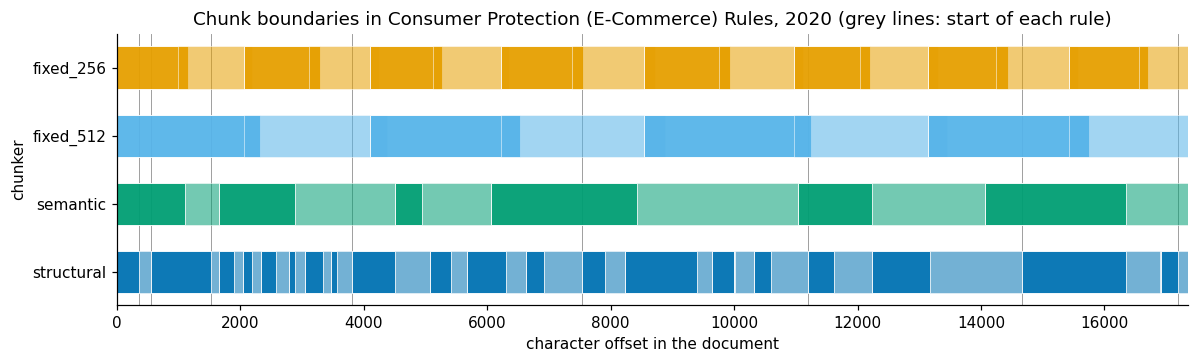

> The E-Commerce Rules have 9 top-level units. The 40 structure-aware chunks start at those lines, or at a sub-rule, clause or sentence inside a long rule; fixed windows cut wherever the token count runs out.

In [13]:
def unit_starts(doc: Doc) -> list:
    """Character offsets where the document's top-level units begin."""
    return sorted(n.char_start for n in doc.nodes if n.is_unit)


def plot_chunk_map(doc_id: str, ax=None, title: str | None = None):
    """Draw each chunker's chunk spans along one document, with unit boundaries."""
    doc = docs[doc_id]
    coll = doc_collection[doc_id]
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 3.4))
    for row, name in enumerate(reversed(CHUNKERS)):
        spans = [(c.char_start, c.char_end) for c in chunks[coll][name] if c.doc_id == doc_id]
        for i, (a, b) in enumerate(spans):
            ax.barh(row, b - a, left=a, height=0.62, color=PALETTE[name],
                    alpha=0.95 if i % 2 == 0 else 0.55, edgecolor="white", linewidth=0.6)
    for x in unit_starts(doc):
        ax.axvline(x, color="#555555", lw=0.6, alpha=0.6, zorder=0)
    ax.set_yticks(range(len(CHUNKERS)))
    ax.set_yticklabels(list(reversed(CHUNKERS)))
    ax.set_xlim(0, len(doc.text))
    ax.set_xlabel("character offset in the document")
    ax.set_ylabel("chunker")
    ax.grid(False)
    ax.set_title(title or f"Chunk boundaries in {doc.short_title} (grey lines: start of each rule)")
    return ax


plot_chunk_map("ecom2020")
plt.tight_layout()
plt.show()
n_units = len(unit_starts(docs["ecom2020"]))
n_struct = sum(c.doc_id == "ecom2020" for c in chunks["consumer_rules"]["structural"])
takeaway(f"The E-Commerce Rules have {n_units} top-level units. The {n_struct} structure-aware chunks start at those lines, or at a sub-rule, "
         f"clause or sentence inside a long rule; fixed windows cut wherever the token count runs out.")

In [14]:
def chunk_stats(collection: str, name: str) -> dict:
    """Size and boundary statistics for one chunker on one collection."""
    cs = chunks[collection][name]
    units = [(n.doc_id, n.char_start, n.char_end) for d in docs.values() if doc_collection[d.doc_id] == collection
             for n in d.nodes if n.is_unit]
    by_doc = defaultdict(list)
    for c in cs:
        by_doc[c.doc_id].append((c.char_start, c.char_end))
    split_units_n = sum(sum(1 for a, b in by_doc[d] if a < e and b > s) > 1 for d, s, e in units)
    crossing = sum(sum(1 for d, s, e in units if d == c.doc_id and s < c.char_end and e > c.char_start) > 1 for c in cs)
    tokens = np.array([c.n_tokens for c in cs])
    return {"collection": COLLECTION_LABELS[collection], "chunker": name, "chunks": len(cs),
            "median tokens": int(np.median(tokens)), "p95 tokens": int(np.percentile(tokens, 95)),
            "units split across chunks": split_units_n / len(units),
            "chunks spanning 2+ units": crossing / len(cs)}


stats = pd.DataFrame([chunk_stats(c, n) for c in COLLECTION_LABELS for n in CHUNKERS])
stats.style.format({"units split across chunks": "{:.0%}", "chunks spanning 2+ units": "{:.0%}"}).hide(axis="index")

collection,chunker,chunks,median tokens,p95 tokens,units split across chunks,chunks spanning 2+ units
Consumer rules,fixed_256,45,256,256,63%,62%
Consumer rules,fixed_512,23,512,512,40%,91%
Consumer rules,semantic,33,248,490,33%,52%
Consumer rules,structural,111,87,248,30%,0%
CS / AI textbooks,fixed_256,984,256,256,98%,9%
CS / AI textbooks,fixed_512,492,512,512,93%,17%
CS / AI textbooks,semantic,842,227,505,95%,6%
CS / AI textbooks,structural,1123,196,405,90%,0%


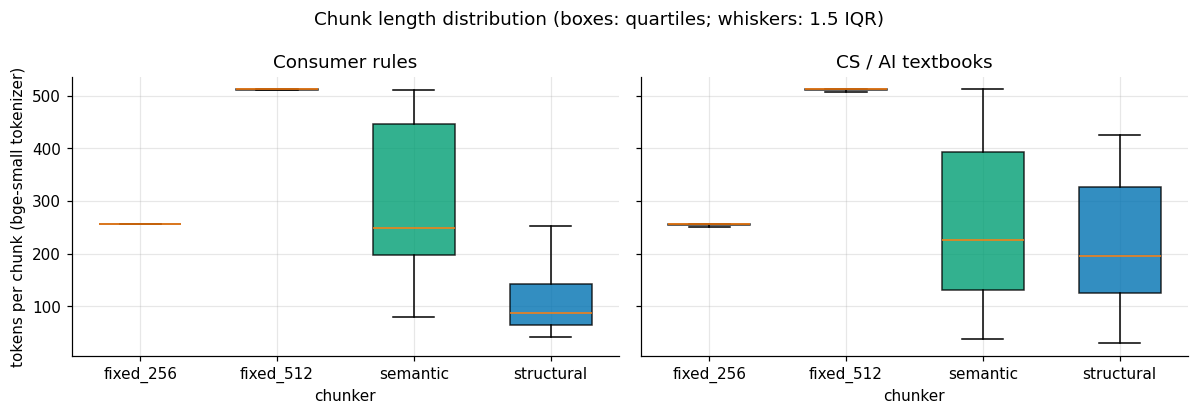

> Structure-aware chunks have a median of 87 tokens on the rules (interquartile range 77) and 196 on the textbooks (IQR 200), while fixed 512-token windows have a median of 512.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, coll in zip(axes, COLLECTION_LABELS):
    data = [[c.n_tokens for c in chunks[coll][n]] for n in CHUNKERS]
    parts = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False)
    for patch, n in zip(parts["boxes"], CHUNKERS):
        patch.set_facecolor(PALETTE[n])
        patch.set_alpha(0.8)
    ax.set_xticks(range(1, len(CHUNKERS) + 1))
    ax.set_xticklabels(CHUNKERS)
    ax.set_title(COLLECTION_LABELS[coll])
    ax.set_xlabel("chunker")
axes[0].set_ylabel("tokens per chunk (bge-small tokenizer)")
fig.suptitle("Chunk length distribution (boxes: quartiles; whiskers: 1.5 IQR)")
plt.tight_layout()
plt.show()
def iqr(coll: str, name: str) -> int:
    q1, q3 = np.percentile([c.n_tokens for c in chunks[coll][name]], [25, 75])
    return int(q3 - q1)


s = stats.set_index(["collection", "chunker"])
takeaway(f"Structure-aware chunks have a median of {s.loc[('Consumer rules', 'structural'), 'median tokens']} tokens on the rules "
         f"(interquartile range {iqr('consumer_rules', 'structural')}) and {s.loc[('CS / AI textbooks', 'structural'), 'median tokens']} on the textbooks "
         f"(IQR {iqr('cs_ai', 'structural')}), while fixed 512-token windows have a median of {s.loc[('Consumer rules', 'fixed_512'), 'median tokens']}.")

## 5. A relevance rule that works for any chunking

Comparing chunkers needs a definition of "relevant chunk" that does not depend on how the text was cut. VeriDex uses the node tree. A chunk *covers* a node when it contains part of that node's own text (the part not inside one of its children). A chunk is relevant to a gold node `g` when it covers `g`, a descendant of `g`, or an ancestor of `g` below chapter level. The ancestor case matters: a chunk holding the lead-in "(3) Every e-commerce entity shall..." of the sub-rule that contains gold clause (a) is useful context. Own text, rather than plain overlap, stops definition (15) from counting as relevant for a question about definition (16) just because both sit in the same section.

In [16]:
class RelevanceJudge:
    """Which gold nodes a chunk is relevant to, from character offsets and parent links."""

    def __init__(self, docs: dict) -> None:
        self.nodes = {nid: n for d in docs.values() for nid, n in d.by_id.items()}
        self.children = defaultdict(list)
        for n in sorted(self.nodes.values(), key=lambda x: (x.doc_id, x.order)):
            if n.parent_id in self.nodes:
                self.children[n.parent_id].append(n.node_id)
        self.span_index = {}  # doc_id -> (starts, ends, node ids) of non-chapter own-text spans
        for d in docs.values():
            rows = [(a, b, n.node_id) for n in d.nodes if n.level != "chapter" for a, b in self.own_spans(d, n)]
            self.span_index[d.doc_id] = (np.array([r[0] for r in rows]), np.array([r[1] for r in rows]),
                                         np.array([r[2] for r in rows], dtype=object))
        self._match = {}

    def own_spans(self, doc: Doc, n: Node) -> list:
        """Character spans of the node's own non-blank text (outside its children)."""
        kids = sorted((self.nodes[c] for c in self.children[n.node_id]), key=lambda k: k.char_start)
        raw, cursor = [], n.char_start
        for k in kids:
            raw.append((cursor, max(cursor, k.char_start)))
            cursor = max(cursor, k.char_end)
        raw.append((cursor, n.char_end))
        spans = []
        for a, b in raw:
            seg = doc.text[a:b]
            if seg.strip():
                lead = len(seg) - len(seg.lstrip())
                spans.append((a + lead, a + lead + len(seg.strip())))
        return spans

    def covered(self, c: Chunk) -> frozenset:
        starts, ends, ids = self.span_index[c.doc_id]
        return frozenset(ids[(starts < c.char_end) & (ends > c.char_start)])

    def matching(self, gold: str) -> frozenset:
        """Nodes whose coverage makes a chunk relevant to `gold`."""
        if gold not in self._match:
            ups, cur = set(), self.nodes[gold].parent_id
            while cur in self.nodes and cur not in ups:
                if self.nodes[cur].level != "chapter":
                    ups.add(cur)
                cur = self.nodes[cur].parent_id
            down, stack = set(), list(self.children[gold])
            while stack:
                x = stack.pop()
                if x not in down:
                    down.add(x)
                    stack.extend(self.children[x])
            self._match[gold] = frozenset({gold} | down | ups)
        return self._match[gold]


judge = RelevanceJudge(docs)
for coll in COLLECTION_LABELS:  # cache what every chunk covers
    for name in CHUNKERS:
        for c in chunks[coll][name]:
            c.covered = judge.covered(c)


def relevant_golds(c: Chunk, golds: list) -> set:
    """Gold nodes that chunk `c` is relevant to."""
    return {g for g in golds if c.covered & judge.matching(g)}

## 6. Retrieval and metrics

One retriever for every chunking: `bge-small-en-v1.5` dense embeddings with cosine similarity, queries prefixed with the bge instruction. The metrics are computed over answerable questions only (unanswerable ones have no gold passage):

- Recall@5: share of a question's gold nodes covered by at least one of the top 5 chunks.
- MRR@10 and nDCG@10: rank quality with binary gains; the ideal ranking for nDCG uses the number of relevant chunks that exist in the corpus.
- Coverage@1024: share of gold nodes inside the top chunks that fit in a 1,024-token context. Recall@k rewards long chunks, because a 512-token window covers more nodes than a 100-token rule; coverage at a fixed token budget removes that advantage.

In [17]:
def recall_at_k(profile: list, golds: list, k: int) -> float:
    covered = set().union(*profile[:k]) if profile[:k] else set()
    return len(covered & set(golds)) / len(set(golds))


def mrr_at_k(profile: list, k: int) -> float:
    return next((1.0 / (i + 1) for i, rel in enumerate(profile[:k]) if rel), 0.0)


def ndcg_at_k(profile: list, k: int, n_relevant_total: int) -> float:
    dcg = sum(1.0 / np.log2(i + 2) for i, rel in enumerate(profile[:k]) if rel)
    ideal_n = min(max(n_relevant_total, sum(1 for rel in profile[:k] if rel)), k)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(ideal_n))
    return dcg / idcg if idcg > 0 else 0.0


def budget_coverage(profile: list, n_tokens: list, golds: list, budget: int) -> float:
    used, n_fit = 0, len(n_tokens)
    for i, n in enumerate(n_tokens):
        if used + n > budget:
            n_fit = i
            break
        used += n
    return recall_at_k(profile, golds, n_fit)


answerable = [q for q in questions if q["answerable"]]
query_vecs = dict(zip([q["uid"] for q in answerable], embed([q["question"] for q in answerable], query=True)))


def evaluate(collection: str, name: str) -> pd.DataFrame:
    """Per-question metrics of dense retrieval over one chunking."""
    cs = chunks[collection][name]
    matrix = embed([c.text for c in cs])
    rows = []
    for q in (q for q in answerable if q["collection"] == collection):
        scores = matrix @ query_vecs[q["uid"]]
        top = np.argsort(-scores, kind="stable")[:50]
        golds = q["gold_node_ids"]
        profile = [relevant_golds(cs[i], golds) for i in top]
        n_rel = sum(1 for c in cs if relevant_golds(c, golds))
        rows.append({"collection": collection, "chunker": name, "uid": q["uid"], "type": q["type"],
                     f"Recall@{K_RECALL}": recall_at_k(profile, golds, K_RECALL),
                     f"MRR@{K_RANK}": mrr_at_k(profile, K_RANK),
                     f"nDCG@{K_RANK}": ndcg_at_k(profile, K_RANK, n_rel),
                     f"Coverage@{BUDGET}": budget_coverage(profile, [cs[i].n_tokens for i in top], golds, BUDGET),
                     "top1_chunk": int(top[0])})
    return pd.DataFrame(rows)


t0 = time.time()
per_q = pd.concat([evaluate(c, n) for c in COLLECTION_LABELS for n in CHUNKERS], ignore_index=True)
print(f"retrieval over {len(CHUNKERS) * len(COLLECTION_LABELS)} chunkings took {time.time() - t0:.0f} s")
METRICS = [f"Recall@{K_RECALL}", f"MRR@{K_RANK}", f"nDCG@{K_RANK}", f"Coverage@{BUDGET}"]
means = per_q.groupby(["collection", "chunker"], sort=False)[METRICS].mean()
means.style.format("{:.3f}").background_gradient(cmap="Blues", axis=0)

retrieval over 8 chunkings took 1333 s


## 7. Paired bootstrap comparison

With 46 and 60 answerable questions, a difference of a few points can be noise. Each question is answered under every chunking, so the right test is paired: resample questions with replacement 1,000 times, recompute the mean difference to the fixed 512-token baseline each time, and read the 2.5th and 97.5th percentiles as a 95% interval.

In [18]:
def paired_bootstrap(a: np.ndarray, b: np.ndarray, n_resamples: int = N_BOOT, seed: int = SEED) -> tuple:
    """Mean of a - b over paired questions and its percentile 95% bootstrap interval."""
    diffs = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(diffs), size=(n_resamples, len(diffs)))
    boot = diffs[idx].mean(axis=1)
    return float(diffs.mean()), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


rows = []
for coll in COLLECTION_LABELS:
    base = per_q[(per_q.collection == coll) & (per_q.chunker == BASELINE)].set_index("uid")
    for name in CHUNKERS:
        if name == BASELINE:
            continue
        other = per_q[(per_q.collection == coll) & (per_q.chunker == name)].set_index("uid").loc[base.index]
        for m in METRICS:
            d, lo, hi = paired_bootstrap(other[m].values, base[m].values)
            rows.append({"collection": coll, "chunker": name, "metric": m, "delta": d, "ci_low": lo, "ci_high": hi,
                         "n": len(base), "excludes_0": lo > 0 or hi < 0})
boot = pd.DataFrame(rows)
boot.pivot_table(index=["collection", "chunker"], columns="metric", values="delta", sort=False).style.format("{:+.3f}")

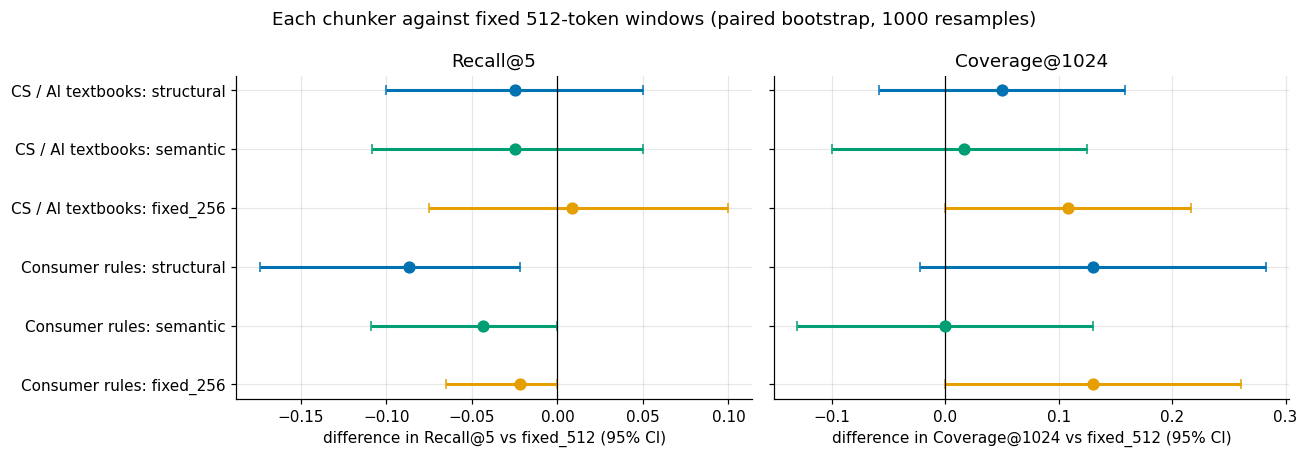

> Structure-aware vs fixed 512 on the rules, Coverage@1024: +0.130 [-0.022, 0.283], the interval includes 0; on the textbooks: +0.050 [-0.058, 0.158], the interval includes 0.

In [19]:
def plot_forest(metrics: list, ax_row) -> None:
    """Point estimates and 95% intervals of the difference to the baseline, one panel per metric."""
    for ax, m in zip(ax_row, metrics):
        sub = boot[boot.metric == m]
        ylabels = []
        for i, (_, r) in enumerate(sub.iterrows()):
            ax.errorbar(r.delta, i, xerr=[[r.delta - r.ci_low], [r.ci_high - r.delta]], fmt="o",
                        color=PALETTE[r.chunker], ms=7, capsize=3, lw=2)
            ylabels.append(f"{COLLECTION_LABELS[r.collection]}: {r.chunker}")
        ax.axvline(0, color="black", lw=0.8)
        ax.set_yticks(range(len(ylabels)))
        ax.set_yticklabels(ylabels)
        ax.invert_yaxis()
        ax.set_xlabel(f"difference in {m} vs {BASELINE} (95% CI)")
        ax.set_title(m)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
plot_forest([f"Recall@{K_RECALL}", f"Coverage@{BUDGET}"], axes)
fig.suptitle(f"Each chunker against fixed 512-token windows (paired bootstrap, {N_BOOT} resamples)")
plt.tight_layout()
plt.show()


def describe_delta(coll: str, name: str, metric: str) -> str:
    """'+0.12 [0.03, 0.21], interval excludes 0' for one comparison."""
    r = boot[(boot.collection == coll) & (boot.chunker == name) & (boot.metric == metric)].iloc[0]
    verdict = "the interval excludes 0" if r.excludes_0 else "the interval includes 0"
    return f"{r.delta:+.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}], {verdict}"


takeaway(f"Structure-aware vs fixed 512 on the rules, Coverage@{BUDGET}: {describe_delta('consumer_rules', 'structural', f'Coverage@{BUDGET}')}; "
         f"on the textbooks: {describe_delta('cs_ai', 'structural', f'Coverage@{BUDGET}')}.")

## 8. One question, four chunkings

Numbers hide what the retriever actually hands to the generator. Below is the top-ranked chunk under each chunker for one legal question where the structure-aware chunk is relevant and the fixed 512-token window is not (the first such question in the file, so the choice is not hand-picked).

In [20]:
def first_contrast_question(coll: str = "consumer_rules"):
    """First question where the structural top-1 chunk is relevant and the fixed_512 top-1 is not."""
    for q in (q for q in answerable if q["collection"] == coll):
        top = {n: chunks[coll][n][int(per_q[(per_q.uid == q["uid"]) & (per_q.chunker == n)].top1_chunk.iloc[0])]
               for n in CHUNKERS}
        if relevant_golds(top["structural"], q["gold_node_ids"]) and not relevant_golds(top[BASELINE], q["gold_node_ids"]):
            return q, top
    return None, None


q, top = first_contrast_question()
if q is not None:
    print(f"Question: {q['question']}\nGold nodes: {', '.join(q['gold_node_ids'])}\n")
    for name in CHUNKERS:
        c = top[name]
        rel = "relevant" if relevant_golds(c, q["gold_node_ids"]) else "not relevant"
        body = docs[c.doc_id].text[c.char_start:c.char_end].replace("\n", " ")
        print(f"[{name}, {c.n_tokens} tokens, {rel}] {body[:260]}...\n")

Question: How many adjournments can the State Commission grant at most?
Gold nodes: commissions2020:r11(8)-prov1

[fixed_256, 256 tokens, relevant] (7) The appellant shall not, except by the leave of the State Commission, urge or be heard in support of any ground of appeal not set forth in the memorandum, but the State Commission in deciding the appeal, need not confine itself to the grounds of appeal set...

[fixed_512, 512 tokens, not relevant] first proviso, the National Commission shall record in writing the reasons of the same at the time of disposal of the said appeal. 15. Number of Members in National Commission.-The National Commission shall consist of a President and not less than four members...

[semantic, 196 tokens, not relevant] IV Strength and vacancies Sanctioned Vacancies Sanctioned Vacancies Strength Strength (a) President (b) Members (c) Reason for Vacancies and Action taken to fill up the same (to be enclosed separately) 2. Performance of State Commission and Distri

In [21]:
# Cover image for the Kaggle listing: the chunk map of the E-Commerce Rules at 1280 x 720 pixels
fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
plot_chunk_map("ecom2020", ax=ax, title="Where four chunkers cut the E-Commerce Rules, 2020")
ax.title.set_fontsize(20)
ax.xaxis.label.set_fontsize(15)
ax.yaxis.label.set_fontsize(15)
ax.tick_params(labelsize=14)
fig.tight_layout()
fig.savefig(WORK_DIR / "cover.png", dpi=100)
plt.close(fig)
print(f"notebook run time so far: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

notebook run time so far: 29.2 min


## 9. What we found

In [22]:
def mean_of(coll: str, name: str, metric: str) -> float:
    return float(means.loc[(coll, name), metric])


n_rules = sum(q["collection"] == "consumer_rules" for q in answerable)
n_text = sum(q["collection"] == "cs_ai" for q in answerable)
cov, rec = f"Coverage@{BUDGET}", f"Recall@{K_RECALL}"
st = stats.set_index(["collection", "chunker"])
findings = [
    f"On the consumer rules ({n_rules} answerable questions), structure-aware chunks put a gold passage inside a 1,024-token context for "
    f"{mean_of('consumer_rules', 'structural', cov):.0%} of gold nodes against {mean_of('consumer_rules', BASELINE, cov):.0%} for fixed 512-token windows "
    f"(difference {describe_delta('consumer_rules', 'structural', cov)}).",
    f"Recall@5 on the rules moved from {mean_of('consumer_rules', BASELINE, rec):.2f} to {mean_of('consumer_rules', 'structural', rec):.2f} "
    f"({describe_delta('consumer_rules', 'structural', rec)}); the whole legal corpus is only {len(chunks['consumer_rules'][BASELINE])} fixed windows, "
    f"so the top five already hold {5 / len(chunks['consumer_rules'][BASELINE]):.0%} of it, which is why coverage at a token budget is the fairer measure here.",
    f"On the textbooks ({n_text} answerable questions) the coverage difference for structure-aware chunks was {describe_delta('cs_ai', 'structural', cov)}, "
    f"and semantic chunks gave {describe_delta('cs_ai', 'semantic', cov)}.",
    f"Fixed 512-token windows split {st.loc[('Consumer rules', 'fixed_512'), 'units split across chunks']:.0%} of the rules across chunks; "
    f"structure-aware chunks split {st.loc[('Consumer rules', 'structural'), 'units split across chunks']:.0%} (long rules and definition lists), "
    f"and {st.loc[('Consumer rules', 'structural'), 'chunks spanning 2+ units']:.0%} of their chunks span two rules, "
    f"against {st.loc[('Consumer rules', 'fixed_512'), 'chunks spanning 2+ units']:.0%} of fixed 512-token windows.",
]
display(Markdown("\n\n".join(findings)))

On the consumer rules (46 answerable questions), structure-aware chunks put a gold passage inside a 1,024-token context for 93% of gold nodes against 80% for fixed 512-token windows (difference +0.130 [-0.022, 0.283], the interval includes 0).

Recall@5 on the rules moved from 1.00 to 0.91 (-0.087 [-0.174, -0.022], the interval excludes 0); the whole legal corpus is only 23 fixed windows, so the top five already hold 22% of it, which is why coverage at a token budget is the fairer measure here.

On the textbooks (60 answerable questions) the coverage difference for structure-aware chunks was +0.050 [-0.058, 0.158], the interval includes 0, and semantic chunks gave +0.017 [-0.100, 0.125], the interval includes 0.

Fixed 512-token windows split 40% of the rules across chunks; structure-aware chunks split 30% (long rules and definition lists), and 0% of their chunks span two rules, against 91% of fixed 512-token windows.

### Limitations

The legal corpus here is four Rules without the parent Act, about 46,000 characters and 46 answerable questions, so intervals are wide. The questions were generated by a 3B model and passed automatic filters; no person reviewed them one by one. One retriever (`bge-small`) is used for every chunking; a stronger retriever or a reranker can shrink the gaps (notebook 2 tests that). Structure-aware chunking depends on a correct parse of the document tree, which this notebook takes as given; on badly extracted PDFs the parse, and the advantage, may not hold.

### Ideas to try

- Change `STRUCT_MAX_TOKENS` to 256 or 512 and watch coverage and chunk counts move.
- Prepend the heading path to fixed windows too, to separate the effect of the breadcrumb from the effect of the boundaries.
- Swap `EMBED_MODEL` for `BAAI/bge-base-en-v1.5` and rerun section 6.
- Retrieve small structural chunks but pass their parent rule to the generator (parent-document retrieval).

### The VeriDex series

1. Chunking legal text for RAG (this notebook)
2. [BM25, dense, RRF fusion and cross-encoder reranking: a retrieval ablation you can rerun](https://www.kaggle.com/code/swapnilshukla007/bm25-dense-rrf-and-reranking-rag-ablation)
3. [Catching unsupported sentences: NLI faithfulness checks for RAG answers](https://www.kaggle.com/code/swapnilshukla007/nli-faithfulness-checks-for-rag-answers)
4. [Teaching a RAG system to abstain: thresholds, coverage and selective accuracy](https://www.kaggle.com/code/swapnilshukla007/teaching-a-rag-system-to-abstain)
5. [RAG in a browser tab: int8 embedding indexes and the size-recall trade-off](https://www.kaggle.com/code/swapnilshukla007/rag-in-a-browser-tab-int8-embedding-indexes)

If you spot a mistake or get different numbers, please say so in the comments; an upvote helps other people find the notebook.